# 1 · Calibrazione della camera

Il master di taratura è una griglia di cerchi con tre cerchi più grandi disposti a "L": l'angolo della L è l'origine del sistema di riferimento. Le immagini sono scattate a distanze `z` note (`z = numero_file · 10 + 50` mm).

Si stima **un solo modello** della camera sui punti delle viste con `z ≤ 350 mm`: matrice di proiezione `P` (3×4), distorsione radiale (`k1`, `k2`, centro) e, come parametri di disturbo, lo spostamento laterale del master in ogni vista (il setup non era perfettamente stabile). Si lavora sui punti, non sulle immagini: nessun doppio *undistort* e un unico sistema di coordinate fino alla misura.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.calibration import fit_camera, model_residuals
from lightsheet3d.grid import find_first_valid_circles_grid, find_origin_index
from lightsheet3d.pipeline import PATTERN_MAX, PATTERN_MIN, calibrate_camera

## Griglia e origine su una vista

pattern 12 righe x 16 colonne, 192 centri; origine = centro n. 85


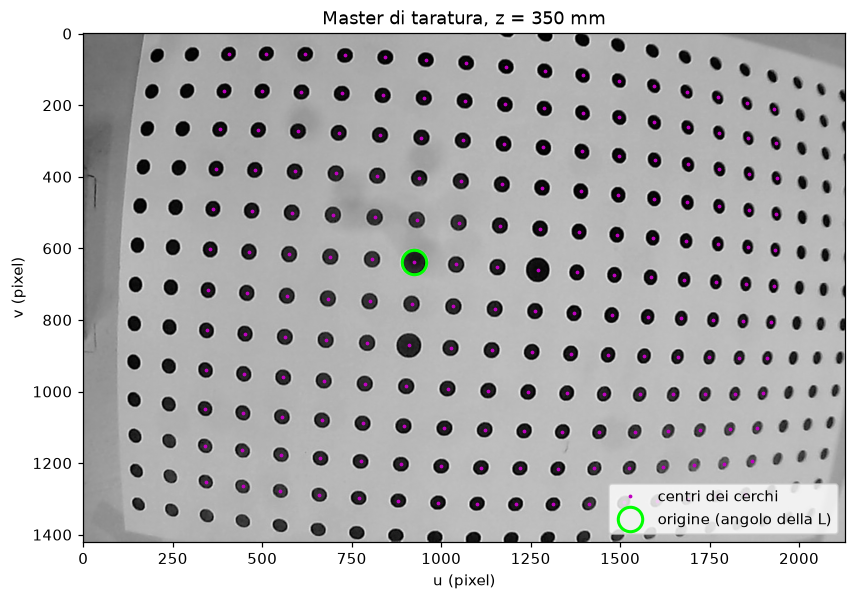

In [2]:
gray = cv.imread(str(DATA / "camera_calibration" / "30_main.jpg"), cv.IMREAD_GRAYSCALE)
pattern, centers = find_first_valid_circles_grid(gray, *PATTERN_MAX, min_size=PATTERN_MIN)
origin = find_origin_index(gray, centers)
print(f"pattern {pattern[1]} righe x {pattern[0]} colonne, {len(centers)} centri; origine = centro n. {origin}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(gray, cmap="gray")
ax.plot(*centers.T, "m.", ms=3, label="centri dei cerchi")
ax.plot(*centers[origin], "o", mfc="none", mec="lime", ms=16, mew=2, label="origine (angolo della L)")
ax.set(xlabel="u (pixel)", ylabel="v (pixel)", title="Master di taratura, z = 350 mm")
ax.grid(False); ax.legend(loc="lower right")
fig.savefig(FIGURES / "camera_grid_origin.png", bbox_inches="tight")

## Modello congiunto

In [3]:
camera = calibrate_camera(DATA / "camera_calibration")
model = camera.model
K = model.P[:, :3]
print("viste usate (z, mm):", sorted(int(z) for z in set(camera.view_ids)), "| scartate:", list(camera.skipped))
print(f"k1 = {model.k[0]:.4f}, k2 = {model.k[1]:.4f}, centro distorsione = ({model.center[0]:.0f}, {model.center[1]:.0f}) px")
print("centro ottico della camera (mm):", (-np.linalg.solve(K, model.P[:, 3])).round(1))
print("\nspostamento laterale stimato del master per vista (mm):")
for z, (dx, dy) in zip(model.views, model.offsets):
    print(f"  z = {z:.0f}:  dx = {dx:+5.1f}  dy = {dy:+5.1f}")

viste usate (z, mm): [300, 310, 320, 330, 340, 350] | scartate: []
k1 = -0.1097, k2 = 0.0110, centro distorsione = (877, 666) px
centro ottico della camera (mm): [ -8.9 -47.1  16.3]

spostamento laterale stimato del master per vista (mm):
  z = 300:  dx =  +0.1  dy =  +1.6
  z = 310:  dx =  -0.3  dy =  -2.2
  z = 320:  dx =  -0.7  dy =  -1.8
  z = 330:  dx =  -1.5  dy =  +3.2
  z = 340:  dx =  +5.9  dy =  -0.1
  z = 350:  dx =  +0.0  dy =  +0.0


scartati 9 centri errati; residuo su 1019 punti: mediana 1.64 px, 95° percentile 8.3 px, rms 3.6 px


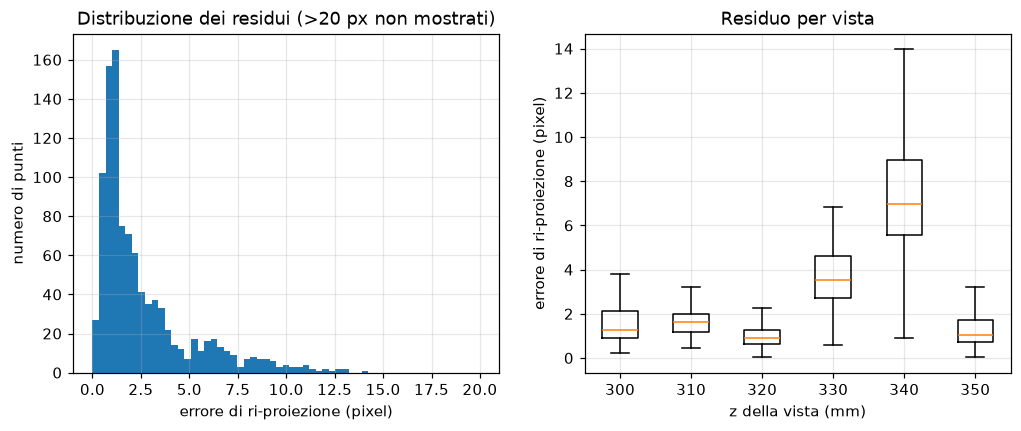

In [4]:
keep = camera.inliers  # i centri sbagliati (residuo > 10 volte la mediana) non entrano nel fit né nelle statistiche
res = model_residuals(model, camera.world, camera.image, camera.view_ids)[keep]
print(f"scartati {int((~keep).sum())} centri errati; residuo su {len(res)} punti: mediana {np.median(res):.2f} px, 95° percentile {np.percentile(res, 95):.1f} px, rms {np.sqrt((res**2).mean()):.1f} px")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.hist(res, bins=np.linspace(0, 20, 60)); a.set(xlabel="errore di ri-proiezione (pixel)", ylabel="numero di punti", title="Distribuzione dei residui (>20 px non mostrati)")
b.boxplot([res[camera.view_ids[keep] == z] for z in model.views], showfliers=False, tick_labels=[f"{z:.0f}" for z in model.views])
b.set(xlabel="z della vista (mm)", ylabel="errore di ri-proiezione (pixel)", title="Residuo per vista")
fig.savefig(FIGURES / "camera_residuals.png", bbox_inches="tight")

## Validazione

Come richiesto dalla traccia, si esclude il 10% dei punti di ogni vista, si ricalibra sul resto e si misura il residuo sui punti esclusi (gli spostamenti del master sono ristimati sul 90%).

In [5]:
world, image, view_ids = camera.world[keep], camera.image[keep], camera.view_ids[keep]
held_out = np.arange(len(world)) % 10 == 0
m90 = fit_camera(world[~held_out], image[~held_out], view_ids[~held_out], (2130, 1420), reference_view=350)
for name, mask in (("calibrazione (90%)", ~held_out), ("validazione (10%)", held_out)):
    r = model_residuals(m90, world[mask], image[mask], view_ids[mask])
    print(f"{name:20s} mediana {np.median(r):.2f} px | 95° percentile {np.percentile(r, 95):.1f} px | rms {np.sqrt((r**2).mean()):.1f} px")

calibrazione (90%)   mediana 1.66 px | 95° percentile 8.3 px | rms 3.6 px
validazione (10%)    mediana 1.69 px | 95° percentile 8.1 px | rms 3.5 px


**Lettura.** La mediana (~1.6 px, circa 0.4 mm sul master) è il valore rappresentativo; l'rms è dominato da una coda di punti con residuo maggiore. Il grafico per vista mostra che la coda viene soprattutto dalle viste a z = 330 e 340 mm (mediana ~3 e ~7 px): ipotesi plausibile, non verificata, è che in quegli scatti il master si sia anche inclinato, effetto che il modello (solo spostamento laterale) non descrive. La mediana sui punti esclusi è praticamente identica a quella di calibrazione (e l'rms è anche più basso, perché i centri anomali capitano per lo più nel 90% usato per il fit): il modello non è in overfitting. Il limite fisico è la stabilità del setup, non l'algoritmo.